In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [4]:
df_memory_main = pd.read_csv("../preprocessing/csv_files/memory_main.csv")
df_memory_lora = pd.read_csv("../preprocessing/csv_files/memory_lora.csv")
df_memory_qlora = pd.read_csv("../preprocessing/csv_files/memory_qlora.csv")
df_memory_lora

,Relative Time (Process),codet5 - system/gpu.6.memoryAllocatedBytes,codet5 - system/gpu.6.memoryAllocatedBytes__MIN,codet5 - system/gpu.6.memoryAllocatedBytes__MAX,codet5 - system/gpu.7.memoryAllocatedBytes,codet5 - system/gpu.7.memoryAllocatedBytes__MIN,codet5 - system/gpu.7.memoryAllocatedBytes__MAX
0,16.325164,62071635968,62071635968,62071635968,62071635968,62071635968,62071635968
1,31.275484,62071635968,62071635968,62071635968,62071635968,62071635968,62071635968
2,46.267865,62071635968,62071635968,62071635968,62071635968,62071635968,62071635968
3,61.377400,62071635968,62071635968,62071635968,62071635968,62071635968,62071635968
4,76.439334,62071635968,62071635968,62071635968,62071635968,62071635968,62071635968
...,...,...,...,...,...,...,...
657,9871.350495,66835841024,66835841024,66835841024,66280554496,66280554496,66280554496
658,9886.259392,66835841024,66835841024,66835841024,66280554496,66280554496,66280554496
659,9901.256424,66835841024,66835841024,66835841024,66280554496,66280554496,66280554496
660,9916.414268,66835841024,66835841024,66835841024,66280554496,66280554496,66280554496


In [5]:
# Main
# Convert relative time to minutes
df_memory_main['Relative Time (Process)'] = df_memory_main['Relative Time (Process)'] / 60

#Convert codet5 - system/gpu.0.memoryAllocatedBytes to GB
df_memory_main['codet5 - system/gpu.1.memoryAllocatedBytes'] = df_memory_main['codet5 - system/gpu.1.memoryAllocatedBytes'] / (1024**3)

#Convert codet5 - system/gpu.1.memoryAllocatedBytes to GB
df_memory_main['codet5 - system/gpu.2.memoryAllocatedBytes'] = df_memory_main['codet5 - system/gpu.2.memoryAllocatedBytes'] / (1024**3)

# LoRA
# Convert relative time to minutes
df_memory_lora['Relative Time (Process)'] = df_memory_lora['Relative Time (Process)'] / 60

#Convert codet5 - system/gpu.0.memoryAllocatedBytes to GB
df_memory_lora['codet5 - system/gpu.6.memoryAllocatedBytes'] = df_memory_lora['codet5 - system/gpu.6.memoryAllocatedBytes'] / (
                                                                           1024 ** 3)

#Convert codet5 - system/gpu.1.memoryAllocatedBytes to GB
df_memory_lora['codet5 - system/gpu.7.memoryAllocatedBytes'] = df_memory_lora['codet5 - system/gpu.7.memoryAllocatedBytes'] / (
                                                                           1024 ** 3)

# QLoRA
# Convert relative time to minutes
df_memory_qlora['Relative Time (Process)'] = df_memory_qlora['Relative Time (Process)'] / 60

#Convert codet5 - system/gpu.0.memoryAllocatedBytes to GB
df_memory_qlora['codet5 - system/gpu.0.memoryAllocatedBytes'] = df_memory_qlora[
                                                                   'codet5 - system/gpu.0.memoryAllocatedBytes'] / (
                                                                           1024 ** 3)

#Convert codet5 - system/gpu.1.memoryAllocatedBytes to GB
df_memory_qlora['codet5 - system/gpu.1.memoryAllocatedBytes'] = df_memory_qlora[
                                                                   'codet5 - system/gpu.1.memoryAllocatedBytes'] / (
                                                                           1024 ** 3)

In [6]:
df_memory_main.drop(columns=["codet5 - system/gpu.1.memoryAllocatedBytes__MAX", 'codet5 - system/gpu.1.memoryAllocatedBytes__MIN', 'codet5 - system/gpu.2.memoryAllocatedBytes__MAX', 'codet5 - system/gpu.2.memoryAllocatedBytes__MIN'], inplace=True)
df_memory_lora.drop(columns=["codet5 - system/gpu.6.memoryAllocatedBytes__MAX", 'codet5 - system/gpu.6.memoryAllocatedBytes__MIN', 'codet5 - system/gpu.7.memoryAllocatedBytes__MAX', 'codet5 - system/gpu.7.memoryAllocatedBytes__MIN'], inplace=True)
df_memory_qlora.drop(columns=["codet5 - system/gpu.0.memoryAllocatedBytes__MAX", 'codet5 - system/gpu.0.memoryAllocatedBytes__MIN', 'codet5 - system/gpu.1.memoryAllocatedBytes__MAX', 'codet5 - system/gpu.1.memoryAllocatedBytes__MIN'], inplace=True)

In [7]:
df_memory_main.rename(columns={
    'Relative Time (Process)': 'Time (Minutes)',
    'codet5 - system/gpu.1.memoryAllocatedBytes': 'GPU 0',
    'codet5 - system/gpu.2.memoryAllocatedBytes': 'GPU 1',
}, inplace=True)

df_memory_lora.rename(columns={
    'Relative Time (Process)': 'Time (Minutes)',
    'codet5 - system/gpu.6.memoryAllocatedBytes': 'GPU 0',
    'codet5 - system/gpu.7.memoryAllocatedBytes': 'GPU 1',
}, inplace=True)

df_memory_qlora.rename(columns={
    'Relative Time (Process)': 'Time (Minutes)',
    'codet5 - system/gpu.0.memoryAllocatedBytes': 'GPU 0',
    'codet5 - system/gpu.1.memoryAllocatedBytes': 'GPU 1',
}, inplace=True)

In [8]:
avg_df_memory_main_gpu0 = df_memory_main['GPU 0'].mean()
avg_df_memory_main_gpu1 = df_memory_main['GPU 1'].mean()
avg_df_memory_main = round((avg_df_memory_main_gpu0 + avg_df_memory_main_gpu1) / 2, 2)
avg_df_memory_main

np.float64(65.45)

In [9]:
avg_df_memory_lora_gp0 = df_memory_lora['GPU 0'].mean()
avg_df_memory_lora_gp1 = df_memory_lora['GPU 1'].mean()
avg_df_memory_lora = round((avg_df_memory_lora_gp0 + avg_df_memory_lora_gp1) / 2, 2)
avg_df_memory_lora

np.float64(61.52)

In [10]:
avg_df_memory_qlora_gp0 = df_memory_qlora['GPU 0'].mean()
avg_df_memory_qlora_gp1 = df_memory_qlora['GPU 1'].mean()
avg_df_memory_qlora = round((avg_df_memory_qlora_gp0 + avg_df_memory_qlora_gp1) / 2, 2)
avg_df_memory_qlora

np.float64(22.96)

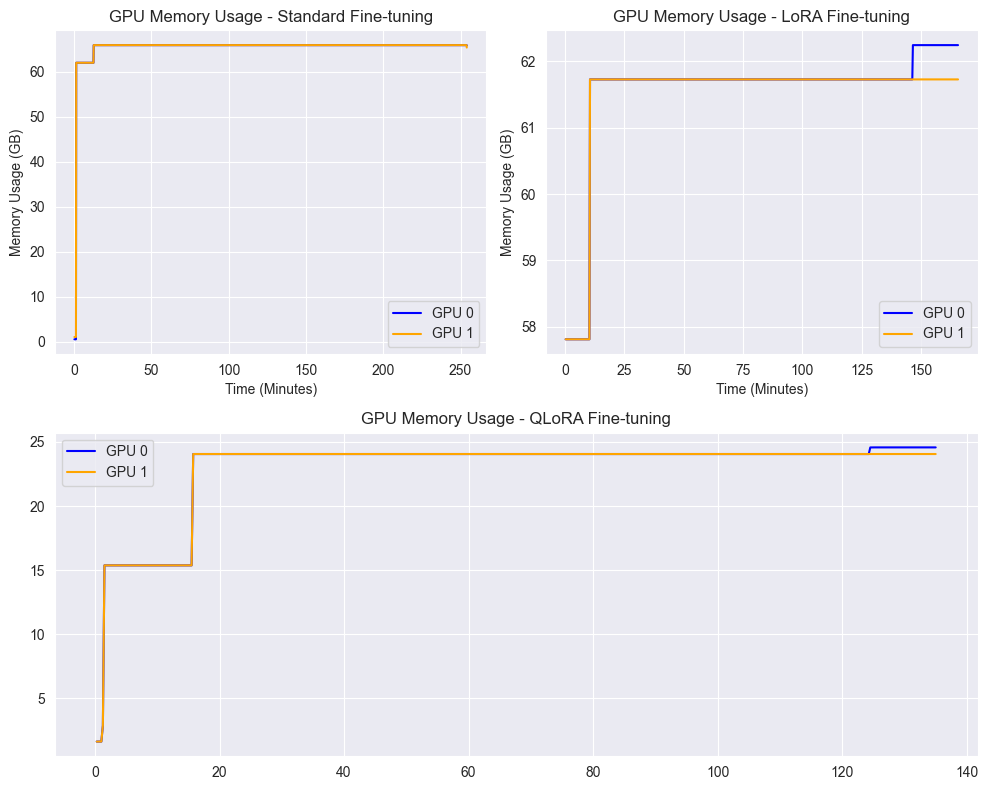

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

# Plot main
ax[0, 0].plot(df_memory_main['Time (Minutes)'] ,df_memory_main['GPU 0'], label='GPU 0', color='blue')
ax[0, 0].plot(df_memory_main['Time (Minutes)'] ,df_memory_main['GPU 1'], label='GPU 1', color='orange')

# Set title and labels
ax[0, 0].set_title('GPU Memory Usage - Standard Fine-tuning')
ax[0, 0].set_xlabel('Time (Minutes)')  # X-axis label
ax[0, 0].set_ylabel('Memory Usage (GB)')  # Y-axis label

# Add legend
ax[0, 0].legend()

# Plot lora
ax[0, 1].plot(df_memory_lora['Time (Minutes)'] ,df_memory_lora['GPU 0'], label='GPU 0', color='blue')
ax[0, 1].plot(df_memory_lora['Time (Minutes)'] ,df_memory_lora['GPU 1'], label='GPU 1', color='orange')
# Set title and labels
ax[0, 1].set_title('GPU Memory Usage - LoRA Fine-tuning')
ax[0, 1].set_xlabel('Time (Minutes)')  # X-axis label
ax[0, 1].set_ylabel('Memory Usage (GB)')  # Y-axis label
# Add legend
ax[0, 1].legend()

# # Plot qlora
# ax[1, 0].plot(df_memory_qlora['Time (Minutes)'] ,df_memory_qlora['GPU 0'], label='GPU 0', color='blue')
# ax[1, 0].plot(df_memory_qlora['Time (Minutes)'] ,df_memory_qlora['GPU 1'], label='GPU 1', color='orange')
# # Set title and labels
# ax[1, 0].set_title('GPU Memory Usage - QLoRA Fine-tuning')
# ax[1, 0].set_xlabel('Time (Minutes)')  # X-axis label
# ax[1, 0].set_ylabel('Memory Usage (GB)')  # Y-axis label
# # Add legend
# ax[1, 0].legend()

# Remove the bottom row subplots
fig.delaxes(ax[1, 0])
fig.delaxes(ax[1, 1])

ax3 = fig.add_subplot(2, 1, 2)
ax3.plot(df_memory_qlora['Time (Minutes)'] ,df_memory_qlora['GPU 0'], label='GPU 0', color='blue')
ax3.plot(df_memory_qlora['Time (Minutes)'] ,df_memory_qlora['GPU 1'], label='GPU 1', color='orange')
ax3.set_title('GPU Memory Usage - QLoRA Fine-tuning')
ax3.legend()

plt.tight_layout()

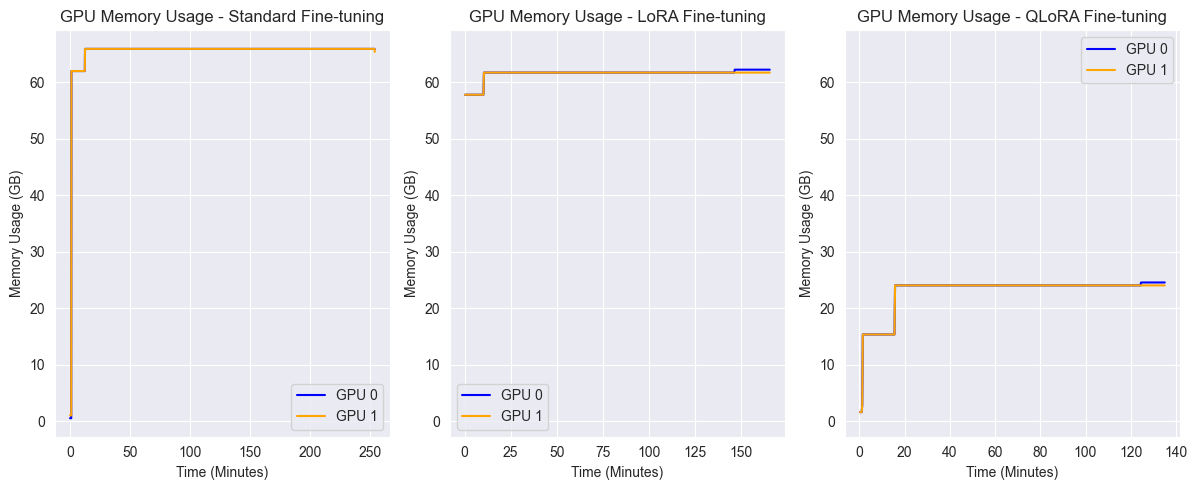

In [12]:
# Create a 3-row layout: (1st row: left, 1st row: right, 2nd row: full-width bottom)
fig, ax = plt.subplots(1, 3, figsize=(12,5))

# Standard Fine-tuning (Top Left)
ax[0].plot(df_memory_main['Time (Minutes)'], df_memory_main['GPU 0'], label='GPU 0', color='blue')
ax[0].plot(df_memory_main['Time (Minutes)'], df_memory_main['GPU 1'], label='GPU 1', color='orange')
ax[0].set_title('GPU Memory Usage - Standard Fine-tuning')
ax[0].set_xlabel('Time (Minutes)')
ax[0].set_ylabel('Memory Usage (GB)')
ax[0].legend()

# LoRA Fine-tuning (Top Right)
ax[1].plot(df_memory_lora['Time (Minutes)'], df_memory_lora['GPU 0'], label='GPU 0', color='blue')
ax[1].plot(df_memory_lora['Time (Minutes)'], df_memory_lora['GPU 1'], label='GPU 1', color='orange')
ax[1].set_title('GPU Memory Usage - LoRA Fine-tuning')
ax[1].set_xlabel('Time (Minutes)')
ax[1].set_ylabel('Memory Usage (GB)')
ax[1].legend()

# QLoRA Fine-tuning (Bottom, Full-Width)
ax[2].plot(df_memory_qlora['Time (Minutes)'], df_memory_qlora['GPU 0'], label='GPU 0', color='blue')
ax[2].plot(df_memory_qlora['Time (Minutes)'], df_memory_qlora['GPU 1'], label='GPU 1', color='orange')
ax[2].set_title('GPU Memory Usage - QLoRA Fine-tuning')
ax[2].set_xlabel('Time (Minutes)')
ax[2].set_ylabel('Memory Usage (GB)')
ax[2].legend()

# Set y-axis scale of ax1 and ax2 to match ax0
y_min, y_max = ax[0].get_ylim()
ax[1].set_ylim(y_min, y_max)
ax[2].set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

In [2]:
df_loss_main = pd.read_csv("../preprocessing/csv_files/loss_main.csv")
df_em_main = pd.read_csv("../preprocessing/csv_files/em_main.csv")
df_bleu_main = pd.read_csv("../preprocessing/csv_files/bleu_main.csv")

df_loss_lora = pd.read_csv("../preprocessing/csv_files/loss_lora.csv")
df_bleu_lora = pd.read_csv("../preprocessing/csv_files/bleu_lora.csv")
df_em_lora = pd.read_csv("../preprocessing/csv_files/em_lora.csv")

df_loss_qlora = pd.read_csv("../preprocessing/csv_files/loss_qlora.csv")
df_bleu_qlora = pd.read_csv("../preprocessing/csv_files/bleu_qlora.csv")
df_em_qlora = pd.read_csv("../preprocessing/csv_files/em_qlora.csv")

In [25]:
df_bleu_main

,Step,codet5 - Bleu_score/valid-per-1000-steps,codet5 - Bleu_score/valid-per-1000-steps__MIN,codet5 - Bleu_score/valid-per-1000-steps__MAX
0,1049,0.999994,0.999994,0.999994
1,2098,1.000000,1.000000,1.000000
2,3147,1.000000,1.000000,1.000000
3,4196,1.000000,1.000000,1.000000
4,5245,1.000000,1.000000,1.000000
5,6294,0.998568,0.998568,0.998568
6,7343,0.999993,0.999993,0.999993
7,8392,0.999995,0.999995,0.999995
8,9441,0.999948,0.999948,0.999948
9,10490,0.999964,0.999964,0.999964


In [3]:
df_loss_main.drop(columns=["codet5 - Loss/valid-per-epoch__MAX", 'codet5 - Loss/valid-per-epoch__MIN'], inplace=True)
df_loss_lora.drop(columns=["codet5 - Loss/valid-per-epoch__MAX", 'codet5 - Loss/valid-per-epoch__MIN'], inplace=True)
df_loss_qlora.drop(columns=["codet5 - Loss/valid-per-epoch__MAX", 'codet5 - Loss/valid-per-epoch__MIN'], inplace=True)
df_em_main.drop(columns=["codet5 - EM_score/valid-per-1000-steps__MAX", 'codet5 - EM_score/valid-per-1000-steps__MIN'], inplace=True)
df_em_lora.drop(columns=["codet5 - EM_score/valid-per-1000-steps__MAX", 'codet5 - EM_score/valid-per-1000-steps__MIN'], inplace=True)
df_em_qlora.drop(columns=["codet5 - EM_score/valid-per-1000-steps__MAX", 'codet5 - EM_score/valid-per-1000-steps__MIN'], inplace=True)
df_bleu_main.drop(columns=["codet5 - Bleu_score/valid-per-1000-steps__MAX", 'codet5 - Bleu_score/valid-per-1000-steps__MIN'], inplace=True)
df_bleu_lora.drop(columns=["codet5 - Bleu_score/valid-per-1000-steps__MAX", 'codet5 - Bleu_score/valid-per-1000-steps__MIN'], inplace=True)
df_bleu_qlora.drop(columns=["codet5 - Bleu_score/valid-per-1000-steps__MAX", 'codet5 - Bleu_score/valid-per-1000-steps__MIN'], inplace=True)

In [4]:
df_loss_main.rename(columns={
    'codet5 - Loss/valid-per-epoch': 'Loss',
}, inplace=True)
df_loss_lora.rename(columns={
    'codet5 - Loss/valid-per-epoch': 'Loss',
}, inplace=True)
df_loss_qlora.rename(columns={
    'codet5 - Loss/valid-per-epoch': 'Loss',
}, inplace=True)
df_em_main.rename(columns={
    'codet5 - EM_score/valid-per-1000-steps': 'Exact Match Score',
}, inplace=True)
df_em_lora.rename(columns={
    'codet5 - EM_score/valid-per-1000-steps': 'Exact Match Score',
}, inplace=True)
df_em_qlora.rename(columns={
    'codet5 - EM_score/valid-per-1000-steps': 'Exact Match Score',
}, inplace=True)
df_bleu_main.rename(columns={
    'codet5 - Bleu_score/valid-per-1000-steps': 'BLEU Score',
}, inplace=True)
df_bleu_lora.rename(columns={
    'codet5 - Bleu_score/valid-per-1000-steps': 'BLEU Score',
}, inplace=True)
df_bleu_qlora.rename(columns={
    'codet5 - Bleu_score/valid-per-1000-steps': 'BLEU Score',
}, inplace=True)


In [5]:
df_em_main

,Step,Exact Match Score
0,1049,0.999941
1,2098,1.000000
2,3147,1.000000
3,4196,1.000000
4,5245,1.000000
5,6294,0.971650
6,7343,0.999822
7,8392,0.999882
8,9441,0.998698
9,10490,0.999112


In [6]:
avg_df_em_main = round(df_em_main['Exact Match Score'].mean(), 4)
avg_df_em_main

np.float64(0.9969)

In [7]:
avg_df_em_lora = round(df_em_lora['Exact Match Score'].mean(), 10)
avg_df_em_lora

np.float64(0.0)

In [8]:
avg_df_bleu_main = round(df_bleu_main['BLEU Score'].mean(), 4)
avg_df_bleu_main

np.float64(0.9998)

In [9]:
avg_df_bleu_lora = round(df_bleu_lora['BLEU Score'].mean(), 4)
avg_df_bleu_lora

np.float64(0.0882)

In [10]:
avg_df_bleu_qlora = round(df_bleu_qlora['BLEU Score'].mean(), 4)
avg_df_bleu_qlora

np.float64(0.1239)

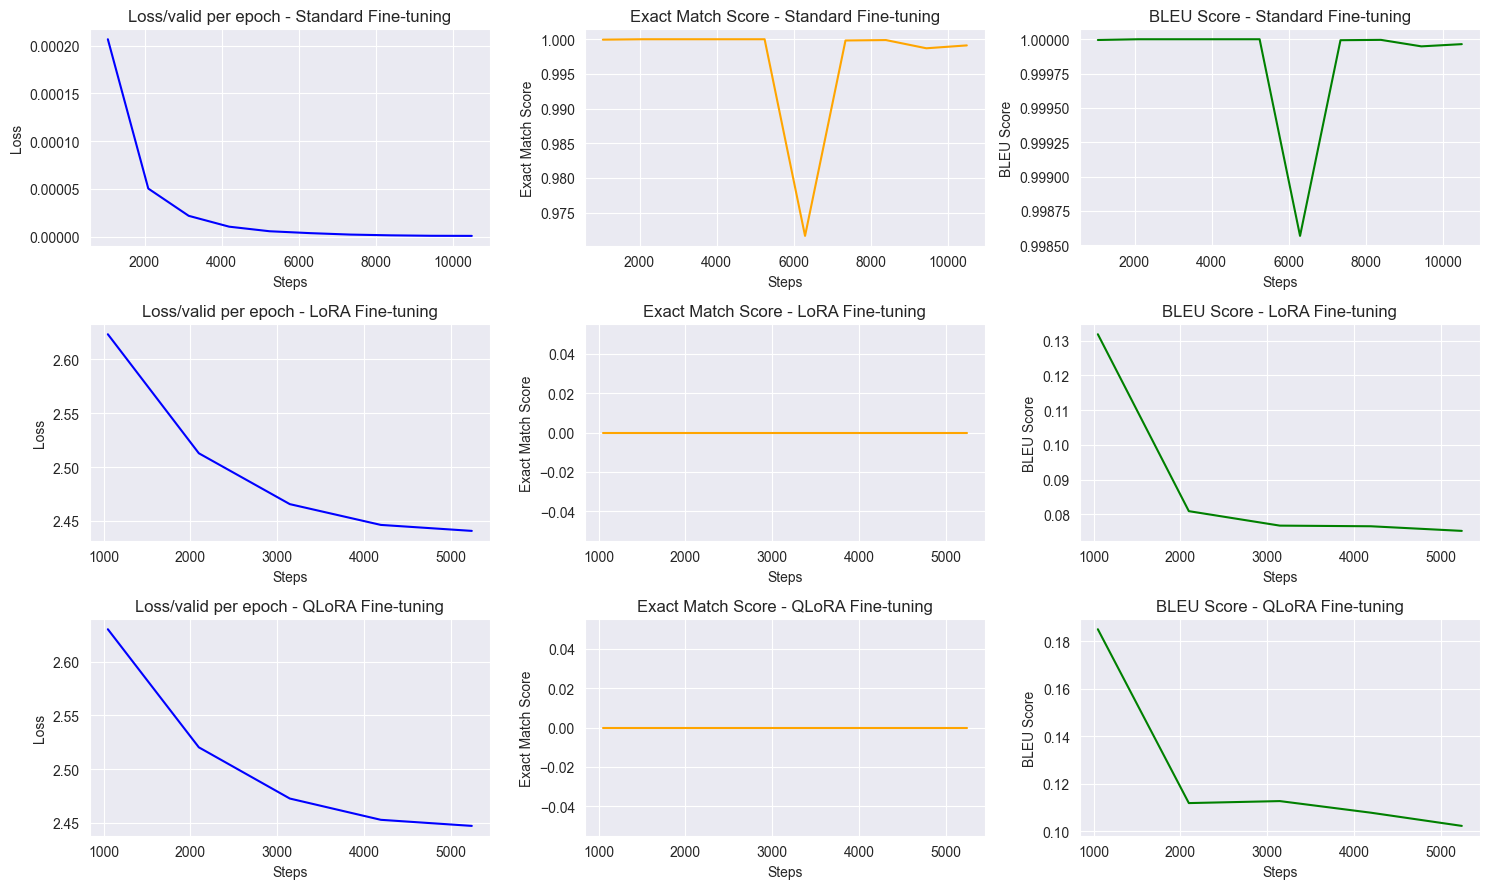

In [13]:
import matplotlib.ticker as ticker

fig, ax = plt.subplots(3, 3, figsize=(15, 9))

# Main
ax[0, 0].plot(df_loss_main['Step'], df_loss_main['Loss'], label='Loss', color='blue')
ax[0, 0].set_title('Loss/valid per epoch - Standard Fine-tuning')
ax[0, 0].set_xlabel('Steps')
ax[0, 0].set_ylabel('Loss')

ax[0, 1].plot(df_em_main['Step'], df_em_main['Exact Match Score'], label='Exact Match Score', color='orange')
ax[0, 1].set_title('Exact Match Score - Standard Fine-tuning')
ax[0, 1].set_xlabel('Steps')
ax[0, 1].set_ylabel('Exact Match Score')

ax[0, 2].plot(df_bleu_main['Step'], df_bleu_main['BLEU Score'], label='BLEU Score', color='green')
ax[0, 2].set_title('BLEU Score - Standard Fine-tuning')
ax[0, 2].set_xlabel('Steps')
ax[0, 2].set_ylabel('BLEU Score')

# def format_func(value, _):
#     return f"{value:.5f}"
#
# # Apply formatter to the first row (Standard Fine-tuning)
# for i in range(3):
#     ax[0, i].yaxis.set_major_formatter(ticker.FuncFormatter(format_func))

# LoRA
ax[1, 0].plot(df_loss_lora['Step'], df_loss_lora['Loss'], label='Loss', color='blue')
ax[1, 0].set_title('Loss/valid per epoch - LoRA Fine-tuning')
ax[1, 0].set_xlabel('Steps')
ax[1, 0].set_ylabel('Loss')

ax[1, 1].plot(df_em_lora['Step'], df_em_lora['Exact Match Score'], label='Exact Match Score', color='orange')
ax[1, 1].set_title('Exact Match Score - LoRA Fine-tuning')
ax[1, 1].set_xlabel('Steps')
ax[1, 1].set_ylabel('Exact Match Score')

ax[1, 2].plot(df_bleu_lora['Step'], df_bleu_lora['BLEU Score'], label='BLEU Score', color='green')
ax[1, 2].set_title('BLEU Score - LoRA Fine-tuning')
ax[1, 2].set_xlabel('Steps')
ax[1, 2].set_ylabel('BLEU Score')


# QLoRA
ax[2, 0].plot(df_loss_qlora['Step'], df_loss_qlora['Loss'], label='Loss', color='blue')
ax[2, 0].set_title('Loss/valid per epoch - QLoRA Fine-tuning')
ax[2, 0].set_xlabel('Steps')
ax[2, 0].set_ylabel('Loss')

ax[2, 1].plot(df_em_qlora['Step'], df_em_qlora['Exact Match Score'], label='Exact Match Score', color='orange')
ax[2, 1].set_title('Exact Match Score - QLoRA Fine-tuning')
ax[2, 1].set_xlabel('Steps')
ax[2, 1].set_ylabel('Exact Match Score')

ax[2, 2].plot(df_bleu_qlora['Step'], df_bleu_qlora['BLEU Score'], label='BLEU Score', color='green')
ax[2, 2].set_title('BLEU Score - QLoRA Fine-tuning')
ax[2, 2].set_xlabel('Steps')
ax[2, 2].set_ylabel('BLEU Score')

plt.tight_layout()
plt.show()



In [26]:
df_loss_trainer = pd.read_csv("../preprocessing/csv_files/loss_trainer.csv")
df_em_trainer = pd.read_csv("../preprocessing/csv_files/em_trainer.csv")
df_bleu_trainer = pd.read_csv("../preprocessing/csv_files/bleu_trainer.csv")

In [27]:
df_bleu_trainer

,train/global_step,Salesforce/codet5-base - _step,Salesforce/codet5-base - _step__MIN,Salesforce/codet5-base - _step__MAX,Salesforce/codet5-base - eval/bleu_score,Salesforce/codet5-base - eval/bleu_score__MIN,Salesforce/codet5-base - eval/bleu_score__MAX
0,1049,0,0,0,0.355015,0.355015,0.355015
1,2098,1,1,1,0.362777,0.362777,0.362777
2,3147,2,2,2,0.366445,0.366445,0.366445
3,4196,3,3,3,0.368220,0.368220,0.368220
4,5245,6,5,7,0.368887,0.368887,0.368887


In [28]:
df_loss_trainer.drop(columns=['Salesforce/codet5-base - _step__MAX', 'Salesforce/codet5-base - _step__MIN', 'Salesforce/codet5-base - eval/loss__MAX', 'Salesforce/codet5-base - eval/loss__MIN', 'Salesforce/codet5-base - _step'], inplace=True)
df_em_trainer.drop(columns=['Salesforce/codet5-base - _step__MAX', 'Salesforce/codet5-base - _step__MIN', 'Salesforce/codet5-base - eval/exact_match__MAX', 'Salesforce/codet5-base - eval/exact_match__MIN', 'Salesforce/codet5-base - _step'], inplace=True)
df_bleu_trainer.drop(columns=['Salesforce/codet5-base - _step__MAX', 'Salesforce/codet5-base - _step__MIN', 'Salesforce/codet5-base - eval/bleu_score__MAX', 'Salesforce/codet5-base - eval/bleu_score__MIN', 'Salesforce/codet5-base - _step'], inplace=True)

In [32]:
df_loss_trainer.rename(columns={
    'Salesforce/codet5-base - eval/loss': 'Loss',
    'train/global_step' : 'Step',
}, inplace=True)
df_em_trainer.rename(columns={
    'Salesforce/codet5-base - eval/exact_match': 'Exact Match Score',
    'train/global_step' : 'Step',
}, inplace=True)
df_bleu_trainer.rename(columns={
    'Salesforce/codet5-base - eval/bleu_score': 'BLEU Score',
    'train/global_step' : 'Step',
}, inplace=True)

In [31]:
df_loss_trainer

,train/global_step,Loss
0,1049,0.305819
1,2098,0.294164
2,3147,0.289602
3,4196,0.287414
4,5245,0.286699


Text(0, 0.5, 'BLEU Score')

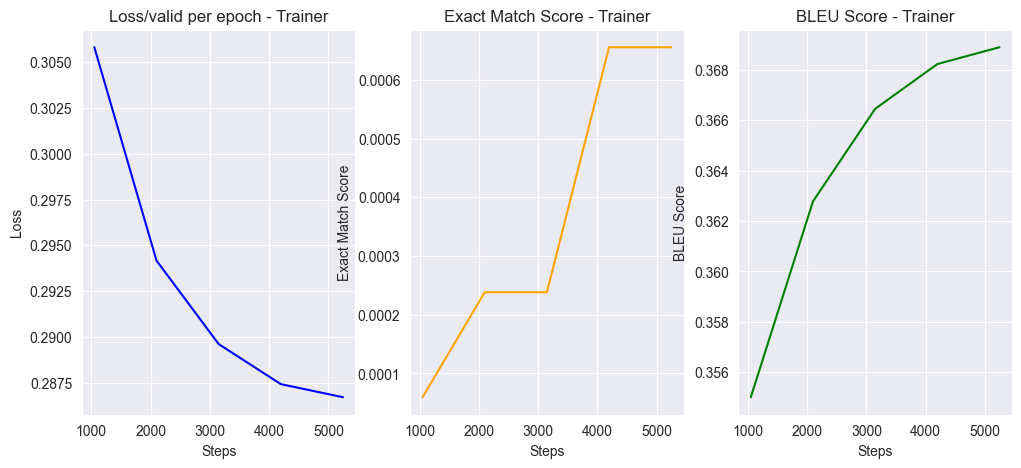

In [41]:
import matplotlib.ticker as ticker

fig, ax = plt.subplots(1, 3, figsize=(12, 5))

# Trainer
ax[0].plot(df_loss_trainer['Step'], df_loss_trainer['Loss'], label='Loss', color='blue')
ax[0].set_title('Loss/valid per epoch - Trainer')
ax[0].set_xlabel('Steps')
ax[0].set_ylabel('Loss')

ax[1].plot(df_em_trainer['Step'], df_em_trainer['Exact Match Score'], label='Exact Match Score', color='orange')
ax[1].set_title('Exact Match Score - Trainer')
ax[1].set_xlabel('Steps')
ax[1].set_ylabel('Exact Match Score')

ax[2].plot(df_bleu_trainer['Step'], df_bleu_trainer['BLEU Score'], label='BLEU Score', color='green')
ax[2].set_title('BLEU Score - Trainer')
ax[2].set_xlabel('Steps')
ax[2].set_ylabel('BLEU Score')

In [42]:
avg_df_em_trainer = round(df_em_trainer['Exact Match Score'].mean(), 4)
avg_df_em_trainer

np.float64(0.0004)

In [44]:
avg_df_bleu_trainer = round(df_bleu_trainer['BLEU Score'].mean(), 4)
avg_df_bleu_trainer

np.float64(0.3643)

In [21]:
df_memory_trainer = pd.read_csv("../preprocessing/csv_files/memory_trainer.csv")

In [22]:
df_memory_trainer

,Relative Time (Process),Salesforce/codet5-base - system/gpu.3.memoryAllocatedBytes,Salesforce/codet5-base - system/gpu.3.memoryAllocatedBytes__MIN,Salesforce/codet5-base - system/gpu.3.memoryAllocatedBytes__MAX,Salesforce/codet5-base - system/gpu.7.memoryAllocatedBytes,Salesforce/codet5-base - system/gpu.7.memoryAllocatedBytes__MIN,Salesforce/codet5-base - system/gpu.7.memoryAllocatedBytes__MAX
0,16.661119,63260655616,63260655616,63260655616,63258558464,63258558464,63258558464
1,32.139252,63260655616,63260655616,63260655616,63258558464,63258558464,63258558464
2,46.513192,63260655616,63260655616,63260655616,63258558464,63258558464,63258558464
3,61.626534,63260655616,63260655616,63260655616,63258558464,63258558464,63258558464
4,76.746025,63260655616,63260655616,63260655616,63258558464,63258558464,63258558464
...,...,...,...,...,...,...,...
581,8731.612532,63260655616,63260655616,63260655616,63258558464,63258558464,63258558464
582,8746.508374,63260655616,63260655616,63260655616,63258558464,63258558464,63258558464
583,8761.819692,63260655616,63260655616,63260655616,63258558464,63258558464,63258558464
584,8776.658553,63260655616,63260655616,63260655616,63258558464,63258558464,63258558464


In [23]:
# Convert relative time to minutes
df_memory_trainer['Relative Time (Process)'] = df_memory_trainer['Relative Time (Process)'] / 60
# Convert codet5 - system/gpu.0.memoryAllocatedBytes to GB
df_memory_trainer['Salesforce/codet5-base - system/gpu.3.memoryAllocatedBytes'] = df_memory_trainer[
    'Salesforce/codet5-base - system/gpu.3.memoryAllocatedBytes'] / (1024 ** 3)
# Convert codet5 - system/gpu.1.memoryAllocatedBytes to GB
df_memory_trainer['Salesforce/codet5-base - system/gpu.7.memoryAllocatedBytes'] = df_memory_trainer[
    'Salesforce/codet5-base - system/gpu.7.memoryAllocatedBytes'] / (1024 ** 3)
# Drop unnecessary columns
df_memory_trainer.drop(columns=["Salesforce/codet5-base - system/gpu.3.memoryAllocatedBytes__MAX",
                                  'Salesforce/codet5-base - system/gpu.3.memoryAllocatedBytes__MIN',
                                  'Salesforce/codet5-base - system/gpu.7.memoryAllocatedBytes__MAX',
                                  'Salesforce/codet5-base - system/gpu.7.memoryAllocatedBytes__MIN'], inplace=True)
# Rename columns
df_memory_trainer.rename(columns={
    'Relative Time (Process)': 'Time (Minutes)',
    'Salesforce/codet5-base - system/gpu.3.memoryAllocatedBytes': 'GPU 0',
    'Salesforce/codet5-base - system/gpu.7.memoryAllocatedBytes': 'GPU 1',
}, inplace=True)
# Calculate average memory usage
avg_df_memory_trainer_gpu0 = df_memory_trainer['GPU 0'].mean()
avg_df_memory_trainer_gpu1 = df_memory_trainer['GPU 1'].mean()
avg_df_memory_trainer = round((avg_df_memory_trainer_gpu0 + avg_df_memory_trainer_gpu1) / 2, 2)
avg_df_memory_trainer

np.float64(58.92)

In [24]:
df_memory_trainer

,Time (Minutes),GPU 0,GPU 1
0,0.277685,58.916077,58.914124
1,0.535654,58.916077,58.914124
2,0.775220,58.916077,58.914124
3,1.027109,58.916077,58.914124
4,1.279100,58.916077,58.914124
...,...,...,...
581,145.526876,58.916077,58.914124
582,145.775140,58.916077,58.914124
583,146.030328,58.916077,58.914124
584,146.277643,58.916077,58.914124


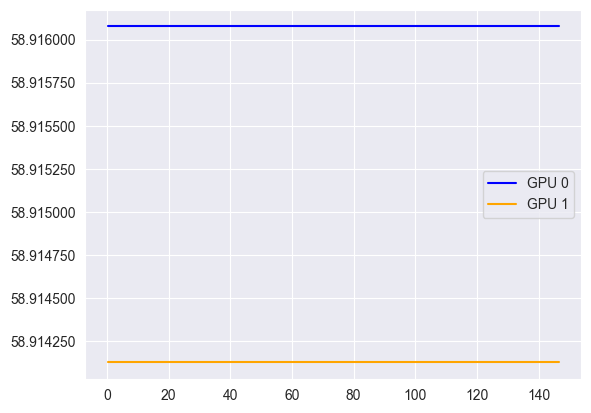

In [30]:
import matplotlib.ticker as mticker
# Plot trainer
plt.plot(df_memory_trainer['Time (Minutes)'] ,df_memory_trainer['GPU 0'], label='GPU 0', color='blue')
plt.plot(df_memory_trainer['Time (Minutes)'] ,df_memory_trainer['GPU 1'], label='GPU 1', color='orange')

plt.gca().yaxis.set_major_formatter(mticker.FormatStrFormatter('%.6f'))  # Adjust decimal places as needed
# Add legend
plt.legend()